In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Load cleaned dataset
df = pd.read_csv(
    r"D:\Project2_GUVI\data\processed\ChargingRecords_cleaned.csv"
)

df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"], errors="coerce"
)
df["Demand"] = pd.to_numeric(
    df["Demand"], errors="coerce"
)

df = df.dropna(subset=["StartDatetime", "Demand"])

print("Dataset shape:", df.shape)
print(df[["StartDatetime", "Demand"]].head())

Dataset shape: (72826, 13)
        StartDatetime  Demand
0 2022-09-15 20:54:00   20.36
1 2022-09-14 20:01:00   10.19
2 2022-09-14 18:54:00    6.78
3 2022-09-29 18:32:00   37.65
4 2022-09-25 19:30:00   33.81


In [2]:
daily_demand = (
    df.set_index("StartDatetime")["Demand"]
    .resample("D")
    .mean()
    .dropna()
)

print("Number of daily observations:", len(daily_demand))
print(daily_demand.head())

Number of daily observations: 366
StartDatetime
2021-09-30    30.483684
2021-10-01    16.786327
2021-10-02    15.351103
2021-10-03    18.904412
2021-10-04    16.529533
Freq: D, Name: Demand, dtype: float64


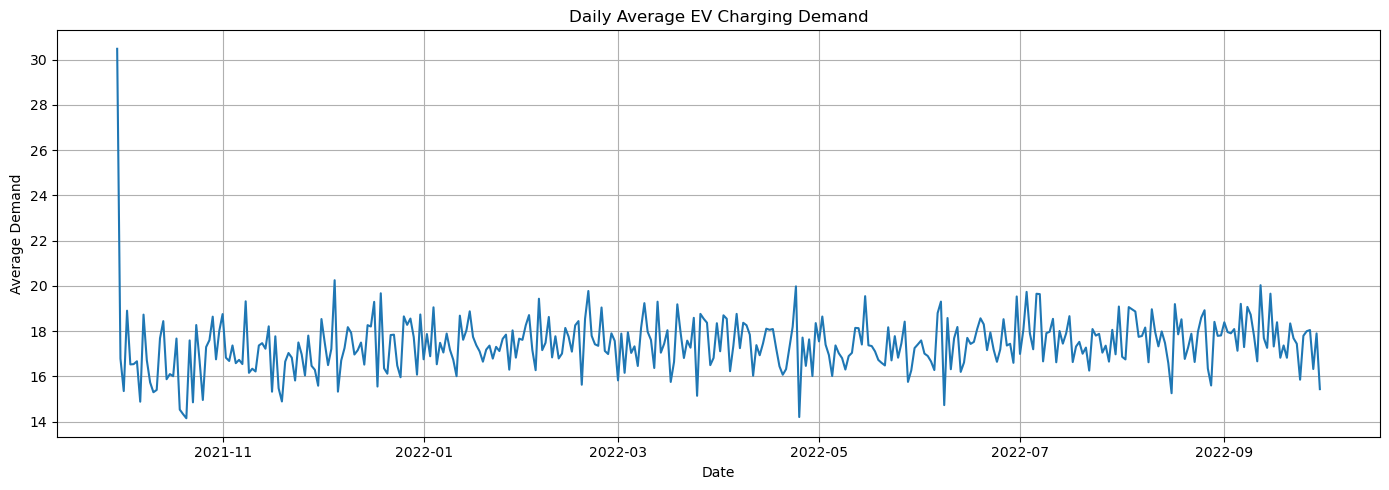

In [3]:
plt.figure(figsize=(14, 5))
plt.plot(daily_demand.index, daily_demand.values)
plt.title("Daily Average EV Charging Demand")
plt.xlabel("Date")
plt.ylabel("Average Demand")
plt.grid(True)
plt.tight_layout()
plt.show()

In [4]:
split_index = int(len(daily_demand) * 0.8)

train = daily_demand.iloc[:split_index]
test = daily_demand.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 292
Testing observations: 74
Training period: 2021-09-30 00:00:00 to 2022-07-18 00:00:00
Testing period: 2022-07-19 00:00:00 to 2022-09-30 00:00:00


In [5]:
window = 7

history = train.tolist()
moving_average_predictions = []

for actual_value in test:
    prediction = np.mean(history[-window:])
    moving_average_predictions.append(prediction)
    history.append(actual_value)

moving_average_predictions = pd.Series(
    moving_average_predictions,
    index=test.index,
    name="Moving Average"
)

print(moving_average_predictions.head())

StartDatetime
2022-07-19    17.514363
2022-07-20    17.643177
2022-07-21    17.499650
2022-07-22    17.474543
2022-07-23    17.239330
Freq: D, Name: Moving Average, dtype: float64


In [6]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

exp_model = SimpleExpSmoothing(
    train,
    initialization_method="estimated"
).fit(optimized=True)

exp_predictions = pd.Series(
    exp_model.forecast(len(test)).to_numpy(),
    index=test.index,
    name="Exponential Smoothing"
)

print(exp_predictions.head())

StartDatetime
2022-07-19    17.549662
2022-07-20    17.549662
2022-07-21    17.549662
2022-07-22    17.549662
2022-07-23    17.549662
Freq: D, Name: Exponential Smoothing, dtype: float64


In [7]:
results = pd.DataFrame([
    {
        "Model": "7-Day Moving Average",
        "MAE": mean_absolute_error(test, moving_average_predictions),
        "RMSE": np.sqrt(mean_squared_error(test, moving_average_predictions))
    },
    {
        "Model": "Simple Exponential Smoothing",
        "MAE": mean_absolute_error(test, exp_predictions),
        "RMSE": np.sqrt(mean_squared_error(test, exp_predictions))
    }
])

print(results.round(4))

                          Model     MAE    RMSE
0          7-Day Moving Average  0.8284  0.9866
1  Simple Exponential Smoothing  0.7738  0.9715


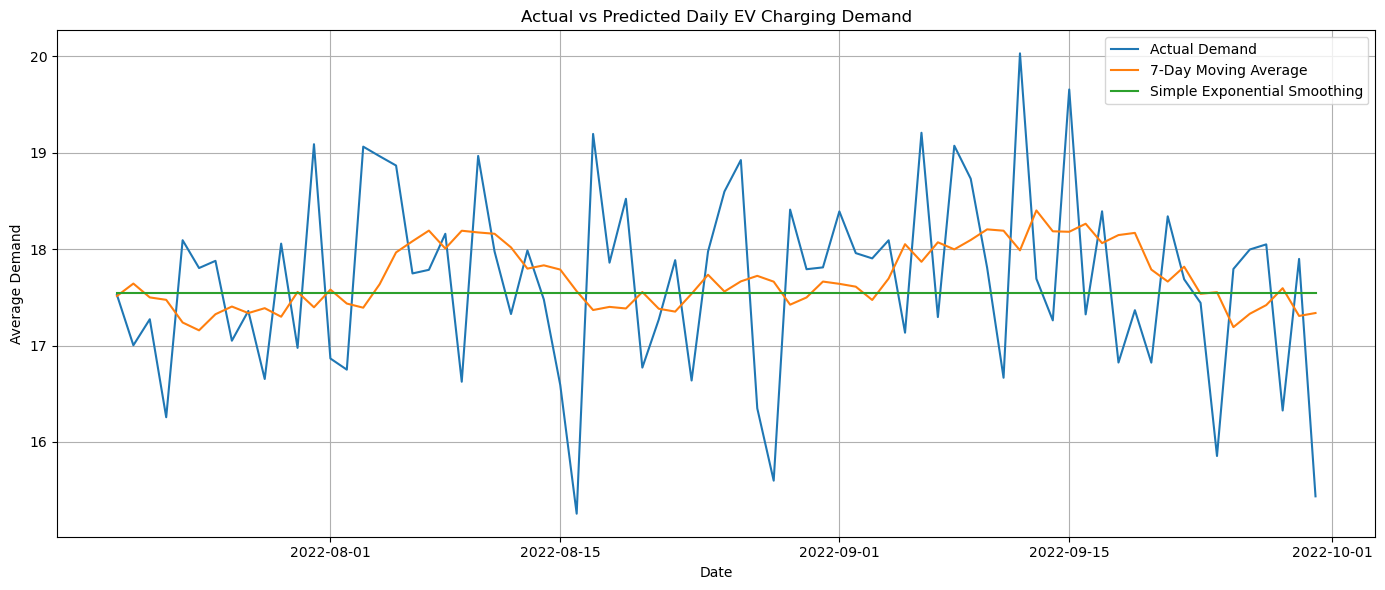

In [8]:
plt.figure(figsize=(14, 6))

plt.plot(test.index, test.values, label="Actual Demand")
plt.plot(
    moving_average_predictions.index,
    moving_average_predictions.values,
    label="7-Day Moving Average"
)
plt.plot(
    exp_predictions.index,
    exp_predictions.values,
    label="Simple Exponential Smoothing"
)

plt.title("Actual vs Predicted Daily EV Charging Demand")
plt.xlabel("Date")
plt.ylabel("Average Demand")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
results.to_csv(
    r"D:\Project2_GUVI\reports\time_series_results.csv",
    index=False
)

print("Time-series results saved successfully.")

Time-series results saved successfully.
